# 02 · Real assets: does the synthetic ranking survive real prices?

`01_synthetic_series` measured every model against an oracle on simulated prices and kept a shortlist: TimesFM 3.0 and 2.5, the random-walk and empirical baselines, and four decision models, each in the elicitation format that worked best for it (fixed there, so it is not chosen here on real outcomes). This notebook asks the same question on eight real instruments across crypto, equities, commodities and FX: *where will the price be 5 observations from now?*

Two things are new on real data:

- **There is no oracle.** Skill is measured against the random walk and the empirical baseline only, and the "fade the move" prior found in 01 is tested against what prices actually did.
- **The models may have seen the test period.** Real prices from 2024 to 2026 can be in a model's training data, so a good score could be recall rather than forecasting. How that is handled is set out in [Look-ahead and memorisation](#Look-ahead-and-memorisation).

Prediction markets are not part of this notebook: a market's question identifies it, and any market that resolved before the models were trained may simply be remembered. They are left to a forward test on markets that resolve after the models' release.

## Setup

In [1]:
import os
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sbench import plots, tsfm
from sbench.backtest import decision_points, load_results, run_forecast_backtest
from sbench.data import Series, cached, load_binance_klines, load_yahoo, truncate
from sbench.elicitation import DirectionChoice, DirectionNoul, ThresholdNoul
from sbench.forecast import blind_task, make_task
from sbench.predictors import DecisionModelPredictor, EmpiricalPredictor, RandomWalkPredictor
from sbench.scoring import per_forecast, reliability, skill_table, summary
from sbench.states import build_price_state
from sbench.tsfm import QuantilePredictor, TimesFM3, TimesFM25

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # weights are cached; never re-check the Hub
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOTS = ROOT / "data" / "snapshots" / "02_real_assets"                 # frozen prices; committed
RESULTS = ROOT / "data" / "results" / "02_real_assets" / "forecasts.csv"   # resumable; committed
CHARTS = ROOT / "outputs" / "02_real_assets"                               # regenerated; not committed

HISTORY_START = "2023-01-01"   # first data; 2023 is history only, never scored
SCORE_START = "2024-01-01"     # first decision point (after TimesFM 3.0's stated data cutoffs)
CHECK_START = "2026-03-01"     # first decision point after the Qwen3.5 release (see below)
END = "2026-09-30"             # last observation, decision points stop HORIZON before it

HORIZON = 5            # forecast 5 observations ahead
STEP = 5               # non-overlapping horizons
MIN_HISTORY = 100      # observations before the first decision point
STATE_LOOKBACK = 60    # rows of history shown to decision models

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## The panel

Eight instruments, two per asset class. Commodities are held through ETFs rather than continuous futures: a futures roll can produce a jump nobody could trade (on 2026-03-10 `CL=F` fell 12.7% while the USO ETF rose 1.5%), and the ETFs close at 16:00 New York like the equities.

| Key | Instrument | Source | Class | Close known at | Notes |
|---|---|---|---|---|---|
| BTC | Bitcoin / USDT | Binance `BTCUSDT` | crypto | 00:00 UTC next day | trades 7 days a week |
| ETH | Ether / USDT | Binance `ETHUSDT` | crypto | 00:00 UTC next day | trades 7 days a week |
| SPY | SPDR S&P 500 ETF | Yahoo `SPY` | equity | 16:00 New York | dividend-adjusted |
| AAPL | Apple shares | Yahoo `AAPL` | equity | 16:00 New York | dividend-adjusted |
| GLD | SPDR Gold Shares | Yahoo `GLD` | commodity | 16:00 New York | |
| USO | United States Oil Fund | Yahoo `USO` | commodity | 16:00 New York | lags spot oil over time (roll costs) |
| EURUSD | Euro / US dollar | Yahoo `EURUSD=X` | FX | provider cut-off | |
| USDJPY | US dollar / yen | Yahoo `USDJPY=X` | FX | provider cut-off | |

"5 observations" is 5 calendar days for crypto and a trading week for everything else; the state tells the models it is 5 *daily observations*. Prices are downloaded once and frozen as CSV snapshots (`sbench.data.cached`): live endpoints keep moving, and Yahoo re-adjusts past prices after every dividend.

In [2]:
PANEL = [
    # key, class, loader, symbol, description shown to the models, unit
    ("BTC", "crypto", "binance", "BTCUSDT", "Bitcoin (BTC) priced in USDT on Binance: daily close price", "USDT"),
    ("ETH", "crypto", "binance", "ETHUSDT", "Ether (ETH) priced in USDT on Binance: daily close price", "USDT"),
    ("SPY", "equity", "yahoo", "SPY", "SPDR S&P 500 ETF Trust (SPY): daily close price", "USD"),
    ("AAPL", "equity", "yahoo", "AAPL", "Apple Inc. (AAPL) shares: daily close price", "USD"),
    ("GLD", "commodity", "yahoo", "GLD", "SPDR Gold Shares ETF (GLD): daily close price", "USD"),
    ("USO", "commodity", "yahoo", "USO", "United States Oil Fund ETF (USO): daily close price", "USD"),
    ("EURUSD", "fx", "yahoo", "EURUSD=X", "Euro / US dollar exchange rate (EUR/USD): daily close", "USD"),
    ("USDJPY", "fx", "yahoo", "USDJPY=X", "US dollar / Japanese yen exchange rate (USD/JPY): daily close", "JPY"),
]
ASSET_CLASS = {key: cls for key, cls, *_ in PANEL}


def load(source: str, symbol: str) -> pd.DataFrame:
    if source == "binance":
        return load_binance_klines(symbol, start=HISTORY_START, end=END)
    return load_yahoo(symbol, start=HISTORY_START, end=pd.Timestamp(END) + pd.Timedelta(days=1))  # end is exclusive


SERIES = []
for key, cls, source, symbol, description, unit in PANEL:
    df = truncate(cached(SNAPSHOTS / f"{key}.csv", load, source, symbol), HISTORY_START, END)
    SERIES.append(Series(key, description, df, unit=unit, meta={"asset_class": cls, "source": source, "symbol": symbol}))

check = pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "rows": len(s), "first": s.df["t"].min().date(),
    "last": s.df["t"].max().date(), "max_gap_days": s.df["t"].diff().max().days,
    "min": s.df["close"].min(), "max": s.df["close"].max(),
} for s in SERIES]).set_index("series")
check

,class,rows,first,last,max_gap_days,min,max
series,,,,,,,
BTC,crypto,1369,2023-01-01,2026-09-30,1,16616.750,124658.540
ETH,crypto,1369,2023-01-01,2026-09-30,1,1200.340,4832.070
SPY,equity,939,2023-01-03,2026-09-30,4,361.858,775.953
AAPL,equity,939,2023-01-03,2026-09-30,4,122.828,341.070
GLD,commodity,939,2023-01-03,2026-09-30,4,168.350,495.900
USO,commodity,939,2023-01-03,2026-09-30,4,58.660,161.860
EURUSD,fx,973,2023-01-02,2026-09-30,5,1.024,1.202
USDJPY,fx,973,2023-01-02,2026-09-30,5,128.026,163.864


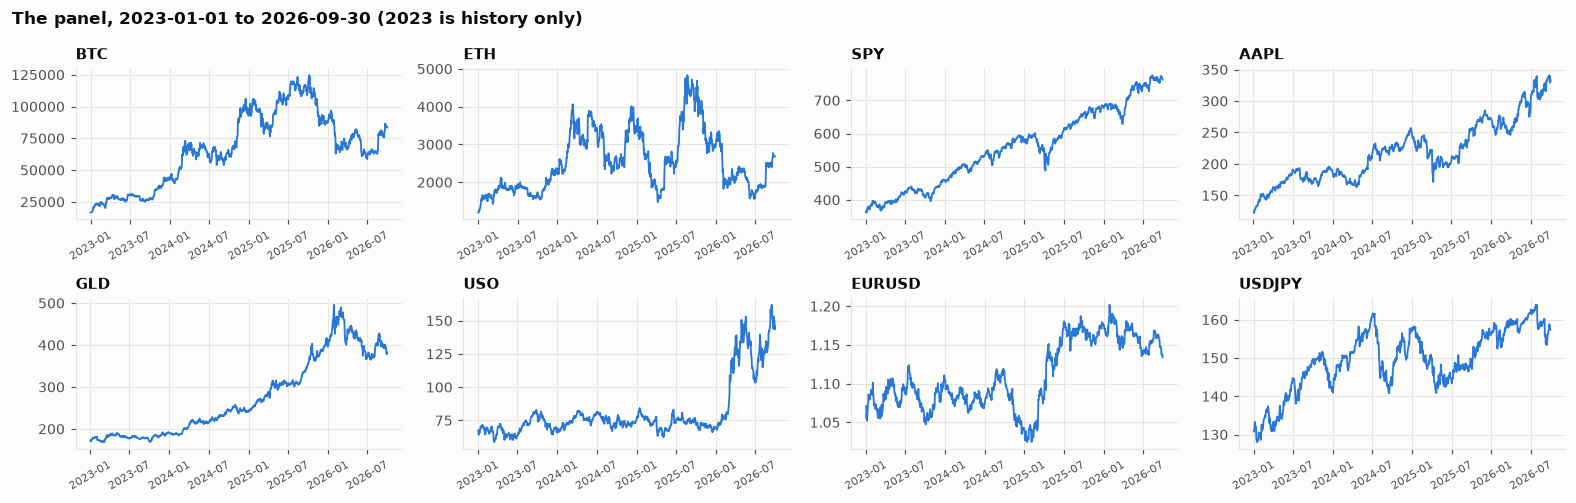

In [3]:
plots.series_panels(SERIES, ncols=4, title=f"The panel, {HISTORY_START} to {END} (2023 is history only)",
                    path=CHARTS / "01_panel.png");

## Look-ahead and memorisation

A forecast is only a forecast if the model could not have known the outcome. On real data that has two sides:

- **No future data in the inputs.** As in 01, every predictor sees only observations at or before the decision time, and outcomes are kept out of the task (`sbench.forecast.ForecastTask`).
- **No future data in the training.** A model trained on text or prices from 2024–2026 may *remember* how these instruments moved. Ideally the test period would start after every model's training cutoff. Here that is not possible:

| Model | Base model | Base released | Model released | Training cutoff stated? |
|---|---|---|---|---|
| clef | Qwen3.8-27B | Aug 2026 | Oct 2026 | no |
| openjev | Qwen family (not named on the card) | | Oct 2026 | no |
| kev-9b | Qwen3.5-9B-Base | Feb 2026 | Sep 2026 (v2) | no |
| lev | Qwen3.5-4B | Feb 2026 | Oct 2026 | no |
| TimesFM 3.0 | trained from scratch | | Aug 2026 | data only: Wikipedia pageviews to Nov 2023, Google Trends to end-2022, GIFT-Eval pretraining sets, synthetic data |

Sources: the model cards and their base models' cards on Hugging Face, checked on 2026-10-20. With no stated cutoffs, a release date is the only safe bound, and the latest (August 2026) would leave about two months of test data. The design therefore removes what a model could recall instead of relying on dates:

1. **Scoring starts in January 2024**, after every data cutoff the TimesFM 3.0 card states; 2023 serves only as history. TimesFM sees numbers only, never names or dates.
2. **Main results use a blind state** (`sbench.forecast.blind_task`): no asset name, no dates, and the 60 closes shown rebased to 100 at the first day. The questions' thresholds are rescaled by the same factor, so the answers map back onto the same grid and the forecasts are scored exactly like the named ones. A model cannot recall a series it cannot identify.
3. **A memorisation check** re-runs the decision models on the same decision points with the named, dated state. The difference between the two measures what names and dates add; it mixes useful context with possible recall, so it is an upper bound on what recall could contribute.
4. **A post-release check** reports decision points from March 2026 on separately. They come after the Qwen3.5 release, so for kev-9b and lev (and for TimesFM) this is a period their pretraining cannot have covered; their named-state results there are the cleanest test of named forecasting available. For clef and openjev, built on Qwen3.8 (August 2026), the same period is not guaranteed to be unseen.

The same decision point, as each state shows it:

In [4]:
STATE = partial(build_price_state, lookback=STATE_LOOKBACK)
btc = SERIES[0]
example = make_task(btc, decision_points(btc, HORIZON, MIN_HISTORY, STEP, start=SCORE_START)[0], HORIZON)


def preview(state: str) -> str:
    lines = state.splitlines()
    return "\n".join(lines[:5] + ["  ..."] + lines[-2:])


print("NAMED\n" + preview(STATE(example)))
print("\nBLIND\n" + preview(STATE(blind_task(example, STATE_LOOKBACK))))
print("\nfirst threshold question, named vs blind:")
for t in (example, blind_task(example, STATE_LOOKBACK)):
    print("  " + ThresholdNoul().questions(t)["q0"]["instructions"])

NAMED
Bitcoin (BTC) priced in USDT on Binance: daily close price
Decision time: 2024-01-01
Current close price: 44,180 USDT
History (oldest → newest):
  2023-11-03: 34,717 USDT
  ...
  2023-12-31: 42,284 USDT
  2024-01-01: 44,180 USDT

BLIND
Asset: daily close price, rebased to 100 at the first day shown
Current close price: 127.26
History (oldest → newest):
  day -59: 100.00
  day -58: 100.99
  ...
  day -1: 121.80
  day 0: 127.26

first threshold question, named vs blind:
  Will the close price 5 daily observations from now be strictly above 39,620 USDT?
  Will the close price 5 daily observations from now be strictly above 114.12?


## Decision points

One decision point every 5 observations from January 2024 (non-overlapping horizons, so outcomes do not overlap), with at least 100 observations of history before each. The last one is 5 observations before the end of the data, so every outcome is observed.

In [5]:
IDXS = {s.key: decision_points(s, HORIZON, min_history=MIN_HISTORY, step=STEP, start=SCORE_START) for s in SERIES}
points = pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "points": len(IDXS[s.key]),
    "first": s.df["t"].iloc[IDXS[s.key][0]].date(), "last": s.df["t"].iloc[IDXS[s.key][-1]].date(),
    "from_" + CHECK_START[:7]: int((s.df["t"].iloc[IDXS[s.key]] >= pd.Timestamp(CHECK_START)).sum()),
} for s in SERIES]).set_index("series")
display(points)
print(f"{points['points'].sum()} decision points in total")

,class,points,first,last,from_2026-03
series,,,,,
BTC,crypto,200,2024-01-01,2026-09-22,42
ETH,crypto,200,2024-01-01,2026-09-22,42
SPY,equity,137,2024-01-02,2026-09-18,28
AAPL,equity,137,2024-01-02,2026-09-18,28
GLD,commodity,137,2024-01-02,2026-09-18,28
USO,commodity,137,2024-01-02,2026-09-18,28
EURUSD,fx,142,2024-01-01,2026-09-21,30
USDJPY,fx,142,2024-01-01,2026-09-21,30


1232 decision points in total


## Predictors

The shortlist from 01, each decision model in its fixed format, asked twice per decision point: blind (main results) and named (memorisation check).

| Predictor | Format | Why it is here (from 01) |
|---|---|---|
| TimesFM 3.0 | deciles | main forecaster: about 80% of the oracle's skill, calibrated |
| TimesFM 2.5 | deciles | previous-generation reference |
| `random_walk` | analytic | the bar to beat |
| `empirical` | past changes | trend extrapolation for free |
| clef | `threshold_noul` | best decision model on distributions and direction; calibrated |
| kev-9b | `threshold_noul` | calibrated; tracks mean reversion |
| lev | `direction_choice` | only direction format with an interval above 0 |
| openjev | `direction_noul` | upper reference for direction; CC BY-NC, reference only |

In [6]:
SHORTLIST = {
    "clef": ThresholdNoul(),
    "kev-9b": ThresholdNoul(),
    "lev": DirectionChoice(include_flat=False),
    "openjev": DirectionNoul(),
}

REFERENCE = [
    RandomWalkPredictor(),
    EmpiricalPredictor(),
    QuantilePredictor(TimesFM3(), name="timesfm3", log_space=True),
    QuantilePredictor(TimesFM25(), name="timesfm2.5", log_space=True),
]


def available(model: str) -> bool:
    # One full-size request (nine questions) before committing hours to a model.
    try:
        DecisionModelPredictor(model, ThresholdNoul(), STATE).predict(example)
        return True
    except Exception as e:  # noqa: BLE001 -- reported, model skipped
        print(f"{model}: unavailable, skipped ({str(e).splitlines()[0][:160]})")
        return False


SERVED = [m for m in SHORTLIST if available(m)]
DECISION = [DecisionModelPredictor(m, SHORTLIST[m], STATE, blind=blind, blind_window=STATE_LOOKBACK)
            for m in SERVED for blind in (True, False)]
print(f"{len(SERVED)}/{len(SHORTLIST)} decision models available: {', '.join(SERVED)}")
print("predictors:", ", ".join(p.name for p in REFERENCE + DECISION))

4/4 decision models available: clef, kev-9b, lev, openjev
predictors: random_walk, empirical, timesfm3, timesfm2.5, clef/threshold_noul/blind, clef/threshold_noul, kev-9b/threshold_noul/blind, kev-9b/threshold_noul, lev/direction_choice/blind, lev/direction_choice, openjev/direction_noul/blind, openjev/direction_noul


## Running the backtest

As in 01: results are appended to a long-format CSV after every forecast, so the run can be interrupted and resumed, and each decision model is loaded once for all instruments and both states. At warm latencies (about 4 s for clef's nine questions, 2 s for kev-9b, under 1 s for lev, about 3 s for openjev) the decision models need roughly 10 s per decision point per state, so the full run takes several hours.

In [7]:
# Model-outer loop: the server loads each decision model once, for both states and all instruments.
GROUPS = [REFERENCE] + [[p for p in DECISION if p.model == m] for m in SERVED]
for preds in GROUPS:
    for s in SERIES:
        run_forecast_backtest(s, preds, HORIZON, RESULTS, IDXS[s.key], verbose=False)
    if preds is REFERENCE:
        tsfm.release()   # TimesFM would otherwise hold ~2.4 GB of GPU memory the server needs

results = load_results(RESULTS)
results = results[results["series"].isin(IDXS) & (results["horizon"] == HORIZON)].reset_index(drop=True)
expected = pd.Series({k: len(v) for k, v in IDXS.items()})
coverage = results.groupby(["predictor", "series"])["t"].nunique().unstack().reindex(columns=expected.index)
missing = coverage.fillna(0).lt(expected, axis=1)   # a series never answered counts as missing
print(f"{results['predictor'].nunique()} predictors; predictor/series pairs with missing decision points: "
      f"{int(missing.to_numpy().sum())}")

12 predictors; predictor/series pairs with missing decision points: 0


## Results

Scores are computed per forecast and compared with the random walk on the same decision points, as in 01 (`lo`, `hi`: 95% paired bootstrap interval of the skill). There is no oracle on real data, so the random walk is the bar and the empirical baseline shows what trend extrapolation alone achieves. Decision models appear twice: `/blind` is the main result, the unsuffixed name is the same model with the named, dated state.

The test period was mostly a rising market for this panel, which matters when reading direction scores: a forecaster that always says "up" would have been right more often than not.

In [8]:
REFS = {"random_walk", "empirical"}


def group(name: str) -> str:
    if name.startswith("timesfm"):
        return "foundation model"
    return "baseline" if name in REFS else "decision model"


def skill_cols(df: pd.DataFrame, metric: str, label: str) -> pd.DataFrame:
    sk = skill_table(df, metric).set_index("predictor")
    return sk[["N", "skill", "lo", "hi"]].rename(columns=lambda c: c if c == "N" else f"{label}_{c}")


per = per_forecast(results)
per["model"] = per["predictor"].str.split("/").str[0]
per["format"] = per["predictor"].str.split("/").str[1].fillna("-")
per["state"] = np.where(per["predictor"].str.endswith("/blind"), "blind state",
                        np.where(per["format"] == "-", "numbers only", "named state"))
per["group"] = per["predictor"].map(group)
per["asset_class"] = per["series"].map(ASSET_CLASS)

full = per[per["crps_n"].notna()]
direction_only = per.loc[per["format"].str.startswith("direction"), "predictor"].unique()
pooled = summary(per, by=("horizon",), ci=False).loc[HORIZON]
brier_up = skill_cols(per, "brier_up", "brier_up")
up_rate = per.loc[per["predictor"] == "random_walk", "up"].mean()

display(Markdown(f"Realised up-rate over all {per['predictor'].eq('random_walk').sum()} decision points: "
                 f"**{up_rate:.1%}**"))
display(Markdown("**Full distributions** (threshold formats, TimesFM, baselines)"))
display(skill_cols(full, "crps_n", "crps")
        .join(brier_up.drop(columns="N"))
        .join(pooled[["cover_80", "coherence", "p_spread"]])
        .sort_values("crps_skill", ascending=False))
display(Markdown("**Direction only** (P(up) formats)"))
display(brier_up.loc[direction_only].sort_values("brier_up_skill", ascending=False))

Realised up-rate over all 1232 decision points: **55.5%**

**Full distributions** (threshold formats, TimesFM, baselines)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80,coherence,p_spread
predictor,,,,,,,,,,
timesfm2.5,1232,-0.006,-0.018,0.005,-0.020,-0.036,-0.003,0.805,0.000,0.960
timesfm3,1232,-0.009,-0.022,0.004,-0.020,-0.039,0.001,0.794,0.000,0.965
empirical,1232,-0.017,-0.031,-0.002,-0.029,-0.057,-0.004,0.776,0.000,0.931
clef/threshold_noul,1232,-0.027,-0.040,-0.014,-0.034,-0.052,-0.015,0.823,0.022,0.876
clef/threshold_noul/blind,1232,-0.047,-0.061,-0.033,-0.045,-0.065,-0.023,0.791,0.035,0.880
kev-9b/threshold_noul,1232,-0.059,-0.075,-0.044,-0.085,-0.112,-0.059,0.879,0.025,0.760
kev-9b/threshold_noul/blind,1232,-0.153,-0.182,-0.124,-0.144,-0.185,-0.102,0.855,0.050,0.744


**Direction only** (P(up) formats)

,N,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,
lev/direction_choice/blind,1232,-0.002,-0.020,0.017
lev/direction_choice,1232,-0.028,-0.054,-0.002
openjev/direction_noul,1232,-0.150,-0.190,-0.110
openjev/direction_noul/blind,1232,-0.363,-0.421,-0.307


### Full distributions against the random walk

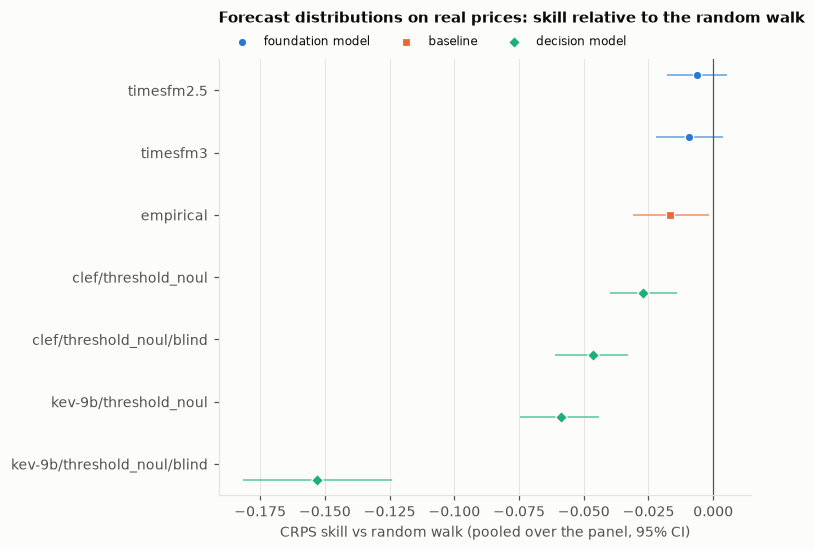

In [9]:
sk = skill_table(full, "crps_n").merge(per[["predictor", "group"]].drop_duplicates(), on="predictor")
plots.dot_plot(sk.sort_values("skill", ascending=False), y="predictor", x="skill", hue="group", lo="lo", hi="hi",
               xlabel="CRPS skill vs random walk (pooled over the panel, 95% CI)",
               title="Forecast distributions on real prices: skill relative to the random walk",
               path=CHARTS / "02_crps_skill.png");

### By asset class

Each cell is skill against the random walk on that class's decision points (two instruments each; blue = better than the random walk, red = worse).

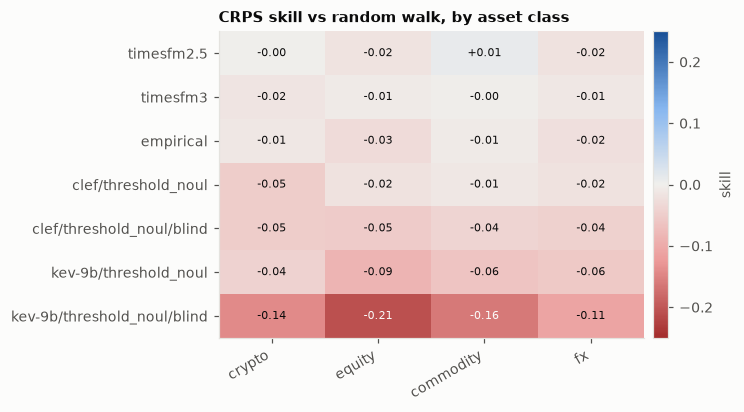

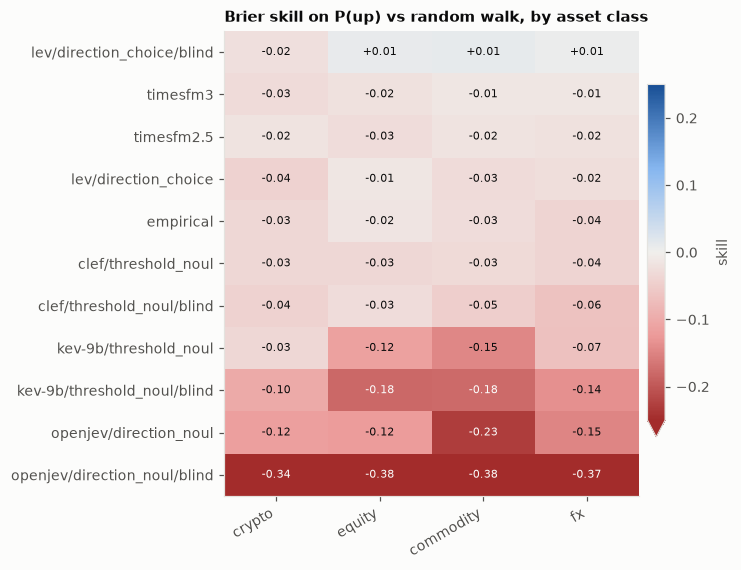

In [10]:
CLASSES = ["crypto", "equity", "commodity", "fx"]


def by_class(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    t = skill_table(df, metric, by=("asset_class",)).pivot(index="predictor", columns="asset_class", values="skill")
    return t[CLASSES].loc[skill_table(df, metric).sort_values("skill", ascending=False)["predictor"]]


plots.heatmap(by_class(full, "crps_n"), span=0.25, title="CRPS skill vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "03_crps_by_class.png")
plots.heatmap(by_class(per, "brier_up"), span=0.25, title="Brier skill on P(up) vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "04_brier_by_class.png");

### Memorisation check: what do names and dates add?

Each decision model answered every decision point twice. The skill of the named state *relative to the blind one* (1 − score named / score blind, paired on decision points) measures what the asset name, the dates and the real price level add. Positive means the named state forecast better. It mixes two things that cannot be separated here: useful context (knowing an asset is Bitcoin says something about its volatility) and recall of the test period.

The split at March 2026 separates them partly: for kev-9b and lev, built on Qwen3.5 (released February 2026), the later period cannot be in the base model's pretraining. If the named advantage were recall, it should shrink there.

period,all decision points,before March 2026,from March 2026
model,,,
clef (Brier on P(up)),0.010,0.012,0.002
clef (CRPS),0.019,0.019,0.019
kev-9b (Brier on P(up)),0.051,0.048,0.063
kev-9b (CRPS),0.082,0.082,0.079
lev (Brier on P(up)),-0.026,-0.029,-0.014
openjev (Brier on P(up)),0.156,0.158,0.148


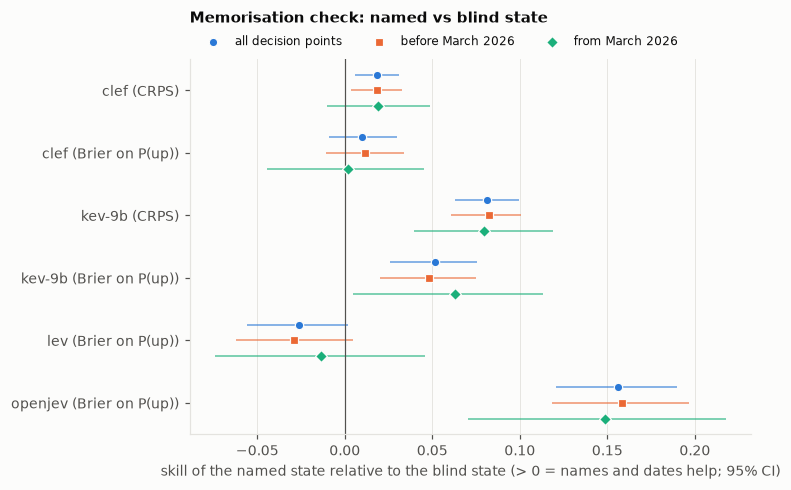

In [11]:
PERIODS = {"all decision points": per["t"].notna(), "before March 2026": per["t"] < CHECK_START,
           "from March 2026": per["t"] >= CHECK_START}
METRICS = {"crps_n": "CRPS", "brier_up": "Brier on P(up)"}
rows = []
for m in SERVED:
    named = f"{m}/{SHORTLIST[m].name}"
    for metric, label in METRICS.items():
        if metric == "crps_n" and not isinstance(SHORTLIST[m], ThresholdNoul):
            continue
        for period, mask in PERIODS.items():
            d = per[mask & per["predictor"].isin([named, named + "/blind"])]
            s = skill_table(d, metric, baseline=named + "/blind").iloc[0]
            rows.append({"model": f"{m} ({label})", "period": period, "named_vs_blind": s["skill"],
                         "lo": s["lo"], "hi": s["hi"], "N": s["N"]})
memo = pd.DataFrame(rows)
plots.dot_plot(memo, y="model", x="named_vs_blind", hue="period", lo="lo", hi="hi",
               xlabel="skill of the named state relative to the blind state (> 0 = names and dates help; 95% CI)",
               title="Memorisation check: named vs blind state", path=CHARTS / "05_named_vs_blind.png")
memo.pivot(index="model", columns="period", values="named_vs_blind")[list(PERIODS)]

### Post-release check: from March 2026

Skill against the random walk on the 256 decision points from March 2026, the period after the Qwen3.5 release. For kev-9b and lev in their named state, and for TimesFM, this is forecasting on data their pretraining cannot have covered. The interval widths show how little 256 points can resolve.

In [12]:
post = per[per["t"] >= CHECK_START]
post_brier = skill_cols(post, "brier_up", "brier_up")
display(Markdown("**Full distributions**"))
display(skill_cols(post[post["crps_n"].notna()], "crps_n", "crps").join(post_brier.drop(columns="N"))
        .sort_values("crps_skill", ascending=False))
display(Markdown("**Direction only**"))
display(post_brier.loc[direction_only].sort_values("brier_up_skill", ascending=False))

**Full distributions**

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,,,,
timesfm3,256,-0.015,-0.041,0.009,-0.012,-0.045,0.020
timesfm2.5,256,-0.025,-0.052,0.001,-0.022,-0.057,0.013
empirical,256,-0.035,-0.062,-0.008,-0.063,-0.117,-0.006
clef/threshold_noul,256,-0.060,-0.089,-0.032,-0.062,-0.107,-0.017
clef/threshold_noul/blind,256,-0.080,-0.113,-0.050,-0.064,-0.110,-0.013
kev-9b/threshold_noul,256,-0.081,-0.115,-0.052,-0.095,-0.148,-0.044
kev-9b/threshold_noul/blind,256,-0.174,-0.246,-0.111,-0.168,-0.257,-0.080


**Direction only**

,N,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,
lev/direction_choice/blind,256,-0.022,-0.070,0.023
lev/direction_choice,256,-0.037,-0.087,0.015
openjev/direction_noul,256,-0.212,-0.311,-0.114
openjev/direction_noul/blind,256,-0.424,-0.559,-0.293


### Do the models fade the move on real prices?

In 01 most decision models expected trends to reverse. Real prices have no oracle, but the question can still be asked against outcomes: decision points are binned into quintiles of the move over the previous 20 observations (in units of recent volatility, so assets are comparable; quintile 1 holds the largest falls, 5 the largest rises), and each model's average P(up) per bin is set against how often the price actually rose. A model whose line falls from left to right fades the move; one whose line rises chases it. The dashed line and its band (95% interval) show what happened.

Slope of the realised up-rate per unit of previous move: -0.008 (95% interval -0.034 to +0.020)

,slope of P(up) per unit of previous move
kev-9b/threshold_noul/blind,-0.060
lev/direction_choice/blind,-0.033
kev-9b/threshold_noul,-0.022
clef/threshold_noul,-0.014
timesfm3,-0.011
realised up-rate,-0.008
clef/threshold_noul/blind,0.010
timesfm2.5,0.010
lev/direction_choice,0.034
empirical,0.038


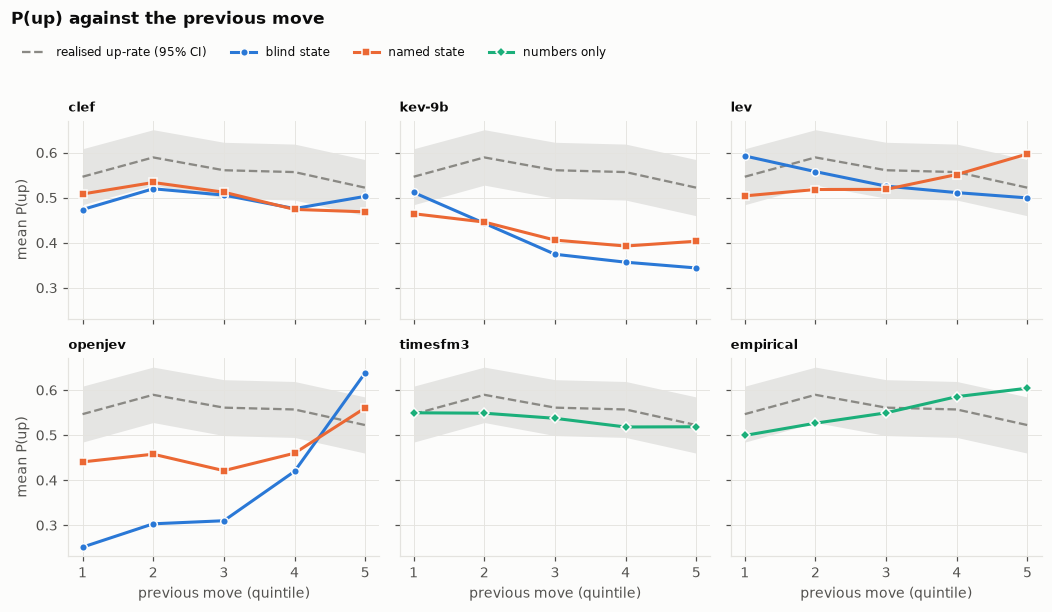

In [13]:
TRAIL = 20
trail = []
for s in SERIES:
    lr = np.log(s.df["close"])
    z = (lr - lr.shift(TRAIL)) / (lr.diff().rolling(30).std() * np.sqrt(TRAIL))
    trail.append(pd.DataFrame({"series": s.key, "t": s.df["t"], "trail_z": z}))
points_z = per.loc[per["predictor"] == "random_walk", ["series", "t", "up"]].merge(pd.concat(trail), on=["series", "t"])
points_z["bin"] = pd.qcut(points_z["trail_z"], 5, labels=False) + 1   # quintiles; 1 = largest fall

fade = per.merge(points_z[["series", "t", "trail_z", "bin"]], on=["series", "t"])
realised = points_z.groupby("bin")["up"].agg(["mean", "size"]).reset_index()
half = 1.96 * np.sqrt(realised["mean"] * (1 - realised["mean"]) / realised["size"])
realised = realised.assign(p_up=realised["mean"], lo=realised["mean"] - half, hi=realised["mean"] + half)

PANELS = SERVED + ["timesfm3", "empirical"]
lines = (fade[fade["model"].isin(PANELS)].groupby(["model", "state", "bin"])["p_up"].mean().reset_index()
         .sort_values("state", key=lambda s: s.map({"blind state": 0, "named state": 1, "numbers only": 2})))
plots.line_panels(lines, "model", "bin", "p_up", hue="state", ref=realised, ref_label="realised up-rate (95% CI)",
                  order=PANELS, xlabel="previous move (quintile)", ylabel="mean P(up)",
                  title="P(up) against the previous move", path=CHARTS / "06_fade_the_move.png")

slopes = {p: np.polyfit(g["trail_z"], g["p_up"], 1)[0] for p, g in fade.dropna(subset=["p_up"]).groupby("predictor")}
slopes["realised up-rate"] = np.polyfit(points_z["trail_z"], points_z["up"].astype(float), 1)[0]
rng = np.random.default_rng(0)
boot = [np.polyfit(*points_z.sample(len(points_z), replace=True, random_state=rng)[["trail_z", "up"]]
                   .astype(float).to_numpy().T, 1)[0] for _ in range(1000)]
display(Markdown(f"Slope of the realised up-rate per unit of previous move: {slopes['realised up-rate']:+.3f} "
                 f"(95% interval {np.quantile(boot, 0.025):+.3f} to {np.quantile(boot, 0.975):+.3f})"))
pd.Series(slopes, name="slope of P(up) per unit of previous move").drop("random_walk").sort_values().to_frame()

### Calibration of the full distributions

Reliability of every threshold answer on real prices, for the predictors that return a full distribution.

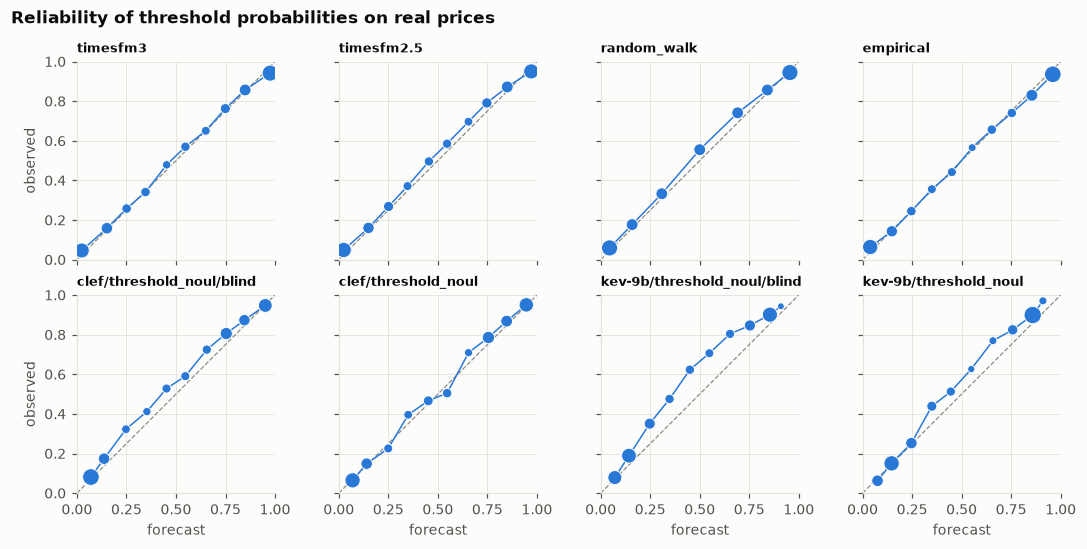

In [14]:
panel = ["timesfm3", "timesfm2.5", "random_walk", "empirical",
         "clef/threshold_noul/blind", "clef/threshold_noul", "kev-9b/threshold_noul/blind", "kev-9b/threshold_noul"]
panel = [p for p in panel if p in set(results["predictor"])]
plots.reliability_panels(reliability(results[results["predictor"].isin(panel)]), order=panel,
                         title="Reliability of threshold probabilities on real prices",
                         path=CHARTS / "07_reliability.png");

### From synthetic to real

The same predictors' pooled skill in 01 (synthetic scenarios with real structure) and here (blind state for the decision models).

In [15]:
r01 = load_results(ROOT / "data" / "results" / "01_synthetic" / "forecasts.csv")
names = ["timesfm3", "timesfm2.5", "empirical"] + [f"{m}/{SHORTLIST[m].name}" for m in SERVED]
per01 = per_forecast(r01[r01["predictor"].isin(names + ["random_walk"])])
main02 = per.assign(predictor=per["predictor"].str.removesuffix("/blind"))
main02 = main02[~per["state"].eq("named state")]


def pooled_skill(p: pd.DataFrame, metric: str) -> pd.Series:
    d = p[p[metric].notna()] if metric == "crps_n" else p
    return skill_table(d, metric).set_index("predictor")["skill"]


both = pd.DataFrame({
    "crps_skill_01": pooled_skill(per01, "crps_n"), "crps_skill_02": pooled_skill(main02, "crps_n"),
    "brier_up_skill_01": pooled_skill(per01, "brier_up"), "brier_up_skill_02": pooled_skill(main02, "brier_up"),
}).reindex(names)
display(Markdown("**Full distributions**"))
display(both.dropna(subset=["crps_skill_01"]))
display(Markdown("**Direction only**"))
display(both[both["crps_skill_01"].isna()][["brier_up_skill_01", "brier_up_skill_02"]])

**Full distributions**

,crps_skill_01,crps_skill_02,brier_up_skill_01,brier_up_skill_02
predictor,,,,
timesfm3,0.110,-0.009,0.157,-0.020
timesfm2.5,0.105,-0.006,0.144,-0.020
empirical,0.093,-0.017,0.136,-0.029
clef/threshold_noul,0.017,-0.047,0.055,-0.045
kev-9b/threshold_noul,-0.015,-0.153,-0.012,-0.144


**Direction only**

,brier_up_skill_01,brier_up_skill_02
predictor,,
lev/direction_choice,0.062,-0.002
openjev/direction_noul,0.014,-0.363


### Runtime

Median wall-clock time per decision point in this run. TimesFM was not yet released from the GPU before the decision models ran (`sbench.tsfm.release`, added after this run), which leaves the model server less memory, so decision-model times here are upper bounds.

In [16]:
(results.drop_duplicates(["series", "predictor", "t"]).groupby("predictor")["latency_s"].median()
 .rename("median seconds per decision point").sort_values().to_frame())

,median seconds per decision point
predictor,
empirical,0.000
random_walk,0.000
timesfm2.5,0.253
timesfm3,0.283
lev/direction_choice/blind,0.297
lev/direction_choice,0.455
openjev/direction_noul/blind,2.704
openjev/direction_noul,3.602
kev-9b/threshold_noul/blind,4.316


## Conclusions

**Real prices leave little to forecast at a 5-observation horizon, and no model found it.** No predictor beats the random walk. TimesFM 3.0 (CRPS skill −0.009, interval −0.022 to +0.004) and 2.5 (−0.006, −0.018 to +0.005) are statistically tied with it and well calibrated (80% intervals cover 79% and 81% of outcomes); the empirical baseline is slightly worse (−0.017, −0.031 to −0.002), and every decision model is worse still. Prices showed neither reversal nor momentum: the realised up-rate is flat across quintiles of the previous move (slope −0.008, interval −0.034 to +0.020). This is what near-efficient markets look like at this horizon, and it explains the drop from 01: TimesFM's skill there came from trends and mean reversion that these returns do not have.

**1. The ranking from 01 held; the gaps closed.** TimesFM first, then `empirical`, then clef, then kev-9b on full distributions, as on synthetic data. On direction, lev in its blind state is the best decision-model answer (Brier skill −0.002, interval −0.020 to +0.017) and openjev the worst (−0.363).

**2. No direction forecast beats a naive base rate.** Prices rose at 55.5% of decision points. A constant forecast of 0.555, which nobody could have known in advance, would have scored +0.012 Brier skill; the best direction forecast scored −0.002 and TimesFM 3.0 −0.020.

**3. Names and dates help, and recall does not explain it.** The named state beats the blind one for clef (+0.019 CRPS), kev-9b (+0.082) and openjev (+0.156 on Brier), and slightly hurts lev (−0.026). For kev-9b the gain is the same after its base model's release as before (+0.079 vs +0.082 in CRPS), where recall is impossible, so it comes from context: knowing which asset it is says something about its behaviour. clef's and openjev's gains are also unchanged after March 2026, although for them that period is not guaranteed unseen. The blind results are therefore a conservative lower bound; even named, no decision model reaches the random walk (clef −0.027).

**4. "Fade the move" is model-specific, not a trait of decision models.** kev-9b still expects moves to reverse and leans bearish (mean P(up) 0.41 blind and 0.42 named, against 55.5% realised), which costs it most on equities and commodities. openjev's blind answers do the opposite and chase the move (slope +0.14) while leaning bearish overall, which makes them the worst forecasts in the panel. clef and TimesFM are roughly flat, as the outcomes were.

**5. Calibration separates the usable models.** TimesFM, `empirical` and clef are close to the diagonal; kev-9b's reliability curve sits above it in both states, i.e. prices ended above its thresholds more often than it predicted.

**Statistical note.** The 1,232 decision points fall on 406 dates. Treating them as independent in the bootstrap is reasonable here: on the same date, the instruments' up/down outcomes correlate only 0.03 on average.

### Going to `03_enrichment`

Price history alone carries no exploitable signal at this horizon, so the question for 03 is whether *added* information creates skill over the random walk:

- **TimesFM 3.0** stays the reference forecaster, with related series as covariates (the variant held back from this notebook).
- **clef** (`threshold_noul`) and **lev** (`direction_choice`) continue as decision models, in the named state: names help, and recall does not appear to drive it. The blind state stays available as a control.
- **kev-9b** and **openjev** are dropped as forecasters: persistent bias (kev-9b) and the worst scores in the panel (openjev, which is also CC BY-NC).
- A 1-observation horizon is added for news, whose effect is concentrated in the first day.

### Caveats

- One horizon and one period (January 2024 to September 2026, a mostly rising market for this panel).
- For clef and openjev, built on Qwen3.8 (August 2026), recall of the test period cannot be fully excluded, only shown not to grow with it.
- `latency_s` in these results was recorded before TimesFM released the GPU between phases; decision-model times are upper bounds (warm figures are in *Running the backtest*).